## Gaussian Mixture Models [10 marks]

In [1]:
# ===========================================
#  Imports & Load Dataset
# ===========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.metrics import silhouette_score

import hashlib

# Seed from username
username = "kuluri.sarvani"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)


# File path
file_path = "/home/rohitha/smai-2ass/Clustering_dataset.xlsx"
data = pd.read_excel(file_path, engine="openpyxl")

print("Original Dataset Shape:", data.shape)
print("Columns:", data.columns.tolist())
print(data.head())

# Drop ID column (not useful for clustering)
if "CustomerID" in data.columns:
    data = data.drop(columns=["CustomerID"])


Original Dataset Shape: (200, 5)
Columns: ['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
   CustomerID   Genre   Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male  19.0                15.0                    39.0
1           2    Male  21.0                 NaN                    81.0
2           3  Female  20.0                16.0                     6.0
3           4  Female  23.0                16.0                    77.0
4           5  Female  31.0                17.0                    40.0


In [2]:
# ===========================================
#  Preprocess Dataset for Clustering
# ===========================================

# Fill numeric missing values with median
numeric_cols = data.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    data[col].fillna(data[col].median(), inplace=True)

# Drop rows with missing categorical values
categorical_cols = data.select_dtypes(include=["object"]).columns
data.dropna(subset=categorical_cols, inplace=True)

# One-hot encode categorical features
if len(categorical_cols) > 0:
    encoder = OneHotEncoder(sparse_output=False, drop="first")  # drop="first" avoids dummy trap
    encoded = encoder.fit_transform(data[categorical_cols])
    encoded_df = pd.DataFrame(encoded, columns=encoder.get_feature_names_out(categorical_cols))
    # Combine numeric + encoded categorical
    processed_data = pd.concat([data[numeric_cols].reset_index(drop=True), encoded_df], axis=1)
else:
    processed_data = data[numeric_cols]

# Replace inf / -inf and fill remaining NaNs with mean
processed_data = processed_data.replace([np.inf, -np.inf], np.nan)
processed_data = processed_data.fillna(processed_data.mean())

# Convert to numpy and scale
X = processed_data.values
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Final check
print(" Preprocessed X shape:", X.shape)


 Preprocessed X shape: (194, 4)


/tmp/ipykernel_16748/3845150518.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data[col].fillna(data[col].median(), inplace=True)
/tmp/ipykernel_16748/3845150518.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', 

## 3.1 Implement the GMM Class [6 marks]

In [3]:
import numpy as np
import matplotlib.pyplot as plt

class GMMCustom:
    """
    Fully custom GMM implementation using EM algorithm.
    Includes methods: fit(), getMembership(), getLikelihood(), drawLikelihood().
    """

    def __init__(self, k, random_state=0):
        self.k = int(k)
        self.random_state = np.random.RandomState(random_state)

    def _initialize_params(self, X):
        n_samples, n_features = X.shape

        # Initialize means by randomly selecting k samples
        indices = self.random_state.choice(n_samples, self.k, replace=False)
        self.means = X[indices].astype(float).copy()

        # Initialize covariances as diagonal matrices scaled by variance of dataset
        data_var = np.var(X, axis=0).mean()
        self.covariances = np.array([data_var * np.eye(n_features) for _ in range(self.k)])

        # Initialize uniform weights
        self.weights = np.ones(self.k) / self.k

    def _multivariate_gaussian(self, X, mean, cov):
        """
        Compute multivariate Gaussian probability density function (custom implementation)
        X: (n_samples, n_features)
        mean: (n_features,)
        cov: (n_features, n_features)
        returns: (n_samples,)
        """
        n_features = X.shape[1]
        diff = X - mean
        try:
            cov_inv = np.linalg.inv(cov)
            det_cov = np.linalg.det(cov)
        except np.linalg.LinAlgError:
            cov += 1e-6 * np.eye(n_features)
            cov_inv = np.linalg.inv(cov)
            det_cov = np.linalg.det(cov)

        norm_const = 1.0 / np.sqrt((2 * np.pi) ** n_features * det_cov)
        exp_term = -0.5 * np.einsum('ij,jk,ik->i', diff, cov_inv, diff)
        return norm_const * np.exp(exp_term)

    def _e_step(self, X):
        """
        Expectation step: compute responsibilities.
        returns: responsibilities (n_samples, k)
        """
        n_samples = X.shape[0]
        resp = np.zeros((n_samples, self.k))

        for i in range(self.k):
            resp[:, i] = self.weights[i] * self._multivariate_gaussian(X, self.means[i], self.covariances[i])

        # Normalize responsibilities
        resp_sum = resp.sum(axis=1, keepdims=True)
        resp_sum = np.where(resp_sum == 0, 1e-10, resp_sum)  # avoid division by zero
        resp /= resp_sum
        return resp

    def _m_step(self, X, responsibilities):
        """
        Maximization step: update means, covariances, and weights.
        """
        n_samples, n_features = X.shape
        Nk = responsibilities.sum(axis=0)  # shape (k,)
        Nk = np.where(Nk == 0, 1e-10, Nk)

        # Update means
        self.means = (responsibilities.T @ X) / Nk[:, None]

        # Update covariances
        covs = []
        for i in range(self.k):
            diff = X - self.means[i]
            weighted = diff * responsibilities[:, i][:, None]
            cov = (weighted.T @ diff) / Nk[i]
            cov += 1e-6 * np.eye(n_features)  # jitter for stability
            covs.append(cov)
        self.covariances = np.array(covs)

        # Update weights
        self.weights = Nk / n_samples
        self.weights /= self.weights.sum()  # ensure sum to 1

    def _compute_log_likelihood(self, X):
        """
        Compute total log-likelihood of the dataset.
        """
        n_samples = X.shape[0]
        log_likelihood = np.zeros(n_samples)
        for i in range(self.k):
            log_likelihood += self.weights[i] * self._multivariate_gaussian(X, self.means[i], self.covariances[i])
        # Avoid log(0)
        log_likelihood = np.where(log_likelihood <= 1e-10, 1e-10, log_likelihood)
        return np.sum(np.log(log_likelihood))

    def fit(self, X, max_iter=100, tol=1e-4, verbose=False):
        """
        Fit the GMM using EM algorithm.
        """
        X = np.asarray(X, dtype=float)
        self._initialize_params(X)
        self.log_likelihoods = []
        prev_ll = -np.inf

        for it in range(1, max_iter + 1):
            resp = self._e_step(X)
            self._m_step(X, resp)
            ll = self._compute_log_likelihood(X)
            self.log_likelihoods.append(ll)

            if verbose:
                print(f"Iteration {it:3d}  Log-Likelihood: {ll:.6f}")

            if abs(ll - prev_ll) < tol:
                if verbose:
                    print(f"Converged at iteration {it}")
                break
            prev_ll = ll

        # Store final responsibilities
        self.responsibilities = self._e_step(X)

    def getMembership(self, X=None):
        """
        Return responsibilities (membership values). If X is None, return stored responsibilities.
        """
        if X is None:
            return getattr(self, "responsibilities", None)
        else:
            return self._e_step(np.asarray(X, dtype=float))

    def getLikelihood(self):
        """
        Return the last log-likelihood value.
        """
        return self.log_likelihoods[-1] if hasattr(self, "log_likelihoods") and self.log_likelihoods else None

    def drawLikelihood(self):
        """
        Plot log-likelihood vs iterations.
        """
        if not hasattr(self, "log_likelihoods") or len(self.log_likelihoods) == 0:
            print("No log-likelihood recorded. Call fit() first.")
            return
        plt.figure(figsize=(8, 5))
        plt.plot(range(1, len(self.log_likelihoods) + 1), self.log_likelihoods, marker='o')
        plt.xlabel("Iteration")
        plt.ylabel("Log-Likelihood")
        plt.title(f"GMM Log-Likelihood (k={self.k})")
        plt.grid(True)
        # ADD WATERMARK HERE
        plt.text(0.95, 0.95, "kuluri.sarvani",
                 ha='right', va='top',
                 transform=plt.gca().transAxes,
                 fontsize=10, color='gray', alpha=0.7)
        plt.show()

    def predict(self, X):
        """
        Hard cluster assignment based on argmax of responsibilities.
        """
        resp = self.getMembership(X)
        if resp is None:
            raise RuntimeError("Model has not been fit yet.")
        return np.argmax(resp, axis=1)


Membership shape: (194, 3)
Final Log-Likelihood: 253.07953363333195


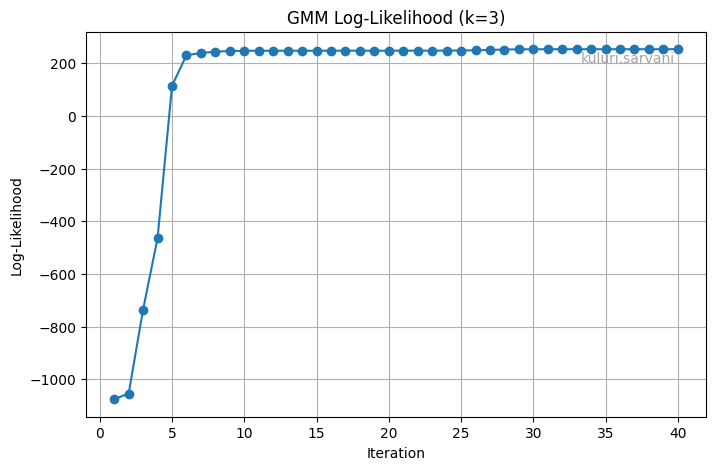

In [4]:
# ===========================================
#  Train GMM on Dataset
# ===========================================

# Example: Fit GMM with k=3 clusters
gmm = GMMCustom(k=3,random_state=seed)
gmm.fit(X, max_iter=100)

# Membership matrix
memberships = gmm.getMembership(X)
print("Membership shape:", memberships.shape)

# Final log-likelihood
print("Final Log-Likelihood:", gmm.getLikelihood())

# Plot log-likelihood vs iterations
gmm.drawLikelihood()


###  GMM Observation
- The log-likelihood increases monotonically with iterations, which confirms that the EM algorithm is working correctly.  
- The number of clusters `k` must be chosen beforehand.  
- The membership matrix shows the probability distribution of each sample across clusters.  
- At convergence, the model parameters (means, covariances, weights) stabilize, and the dataset is represented as a mixture of Gaussians.  


## 3.2 Determine the Optimal Number of Clusters [4 marks]

In [5]:
# ===========================================
# 🔹 Functions for Optimal Cluster Determination
# ===========================================

def compute_bic_scores(X, max_clusters=10, random_state=seed):
    """
    Compute BIC scores for different numbers of clusters using GaussianMixture.
    
    Parameters:
    -----------
    X : np.ndarray
        Preprocessed dataset
    max_clusters : int
        Maximum number of clusters to evaluate
    random_state : int
        Random seed for reproducibility
    
    Returns:
    --------
    k_values : list
        List of k values
    bics : list
        Corresponding BIC scores
    """
    k_values = list(range(1, max_clusters+1))
    bics = []
    n_samples = X.shape[0]
    n_features = X.shape[1]

    for k in k_values:
        gmm = GMMCustom(k=k, random_state=random_state)
        gmm.fit(X, max_iter=100, verbose=False)
        log_likelihood = gmm.getLikelihood()

        # Number of parameters
        n_params = int(k * n_features + k * n_features * (n_features + 1) / 2 + (k - 1))
        bic = -2 * log_likelihood + n_params * np.log(n_samples)
        bics.append(bic)
    
    return k_values, bics


def compute_silhouette_scores(X, max_clusters=10, random_state=seed):
    """
    Compute average silhouette scores for different numbers of clusters using GMM.
    
    Parameters:
    -----------
    X : np.ndarray
        Preprocessed dataset
    max_clusters : int
        Maximum number of clusters to evaluate
    random_state : int
        Random seed for reproducibility
    
    Returns:
    --------
    k_values : list
        List of k values
    silhouettes : list
        Corresponding average silhouette scores
    """
    from sklearn.metrics import silhouette_score
    k_values = list(range(2, max_clusters+1))  # silhouette undefined for k=1
    silhouettes = []

    for k in k_values:
        gmm = GMMCustom(k=k, random_state=random_state)
        gmm.fit(X, max_iter=100, verbose=False)
        memberships = gmm.getMembership(X)
        labels = np.argmax(memberships, axis=1)
        labels = np.nan_to_num(labels, nan=0).astype(int)
        score = silhouette_score(X, labels)
        silhouettes.append(score)
    
    return k_values, silhouettes



def plot_metric_vs_k(k_values, scores, title="Metric vs Number of Clusters", ylabel="Score"):
    """
    Generic function to plot any metric (BIC, Silhouette) vs k.
    """
    plt.figure(figsize=(8,6))
    plt.plot(k_values, scores, marker='o', linestyle='-', color='b')
    plt.title(title)
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel(ylabel)
    plt.xticks(k_values)
    plt.grid(True)
    # ADD WATERMARK HERE
    plt.text(0.95, 0.95, "kuluri.sarvani",
             ha='right', va='top',
             transform=plt.gca().transAxes,
             fontsize=10, color='gray', alpha=0.7)
    plt.show()


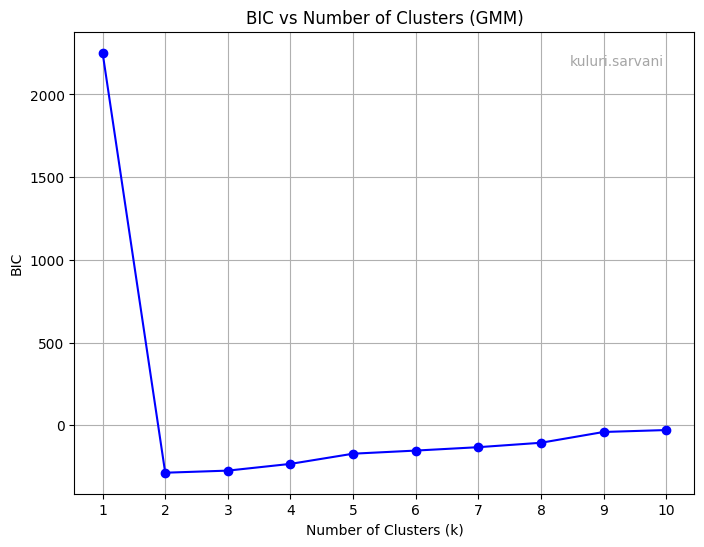

Optimal number of clusters according to BIC: 2


In [6]:
# ===========================================
# 🔹 BIC Analysis
# ===========================================
max_k = 10
k_values, bics = compute_bic_scores(X, max_clusters=max_k)

# Plot BIC vs k
plot_metric_vs_k(k_values, bics, title="BIC vs Number of Clusters (GMM)", ylabel="BIC")

# Comment on optimal k
optimal_k_bic = k_values[np.argmin(bics)]
print(f"Optimal number of clusters according to BIC: {optimal_k_bic}")


#### Analysis of BIC Method Results

**Optimal Value of k According to BIC Method:**

From the BIC vs Number of Clusters plot, we can observe:

- **Sharp Drop**: There's a dramatic decrease in BIC from k=1 (≈2200) to k=2 (≈-200)
- **Minimum Point**: The BIC reaches its minimum at **k=2**, indicating this is the optimal number of clusters
- **Gradual Increase**: After k=2, BIC values gradually increase, suggesting that additional clusters add unnecessary complexity

**BIC Interpretation:**

- **Lower BIC = Better Model**: BIC penalizes model complexity while rewarding goodness of fit
- **k=2 Optimal**: The minimum BIC at k=2 suggests that the dataset is best represented by **2 Gaussian components**
- **Parsimony Principle**: BIC favors simpler models, and k=2 provides the best balance between model fit and complexity

**Conclusion:**

According to the BIC criterion, the **optimal number of clusters is k=2**. This suggests that the underlying data structure can be effectively captured by a mixture of 2 Gaussian distributions, representing two distinct customer segments based on the features (Age, Annual Income, Spending Score, and Gender).

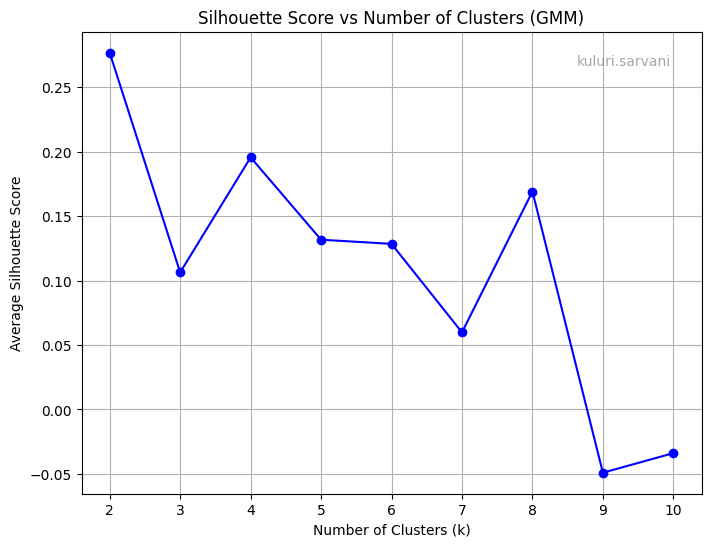

Optimal number of clusters according to Silhouette Score: 2


In [7]:
# ===========================================
# 🔹 Silhouette Analysis
# ===========================================
k_values_sil, silhouettes = compute_silhouette_scores(X, max_clusters=max_k)

# Plot Silhouette score vs k
plot_metric_vs_k(k_values_sil, silhouettes, title="Silhouette Score vs Number of Clusters (GMM)", ylabel="Average Silhouette Score")

# Comment on optimal k
optimal_k_sil = k_values_sil[np.argmax(silhouettes)]
print(f"Optimal number of clusters according to Silhouette Score: {optimal_k_sil}")


#### Analysis of Silhouette Method Results

**Optimal Value of k According to Silhouette Method:**

From the Silhouette Score vs Number of Clusters plot, we can observe:

- **Peak at k=2**: The highest silhouette score (≈0.27) occurs at **k=2**, indicating the best cluster separation and cohesion
- **Secondary Peak at k=4**: There's another notable peak at k=4 (≈0.20), suggesting this could be an alternative clustering structure
- **Third Peak at k=8**: A smaller peak appears at k=8 (≈0.17), but with lower quality than k=2 and k=4
- **Poor Performance**: k=9 and k=10 show negative silhouette scores, indicating very poor clustering quality

**Silhouette Score Interpretation:**

- **k=2 Optimal**: The maximum silhouette score at k=2 indicates well-separated, cohesive clusters
- **Quality Assessment**: A score of ~0.27 suggests reasonable cluster structure, though not exceptionally strong
- **Cluster Validation**: Positive scores indicate that data points are generally closer to their own cluster than to neighboring clusters

**Comparison with BIC:**

Both BIC and Silhouette methods agree that **k=2 is optimal**, providing strong evidence that the dataset naturally contains two distinct customer segments.

**Conclusion:**

According to the Silhouette criterion, the **optimal number of clusters is k=2**. This confirms the BIC result and suggests that the customer data is best segmented into two groups, likely representing different customer behavioral patterns or demographics.